In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from adjustText import adjust_text

In [2]:
pth = os.path.join('..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'development', 'modeling')
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'mesencoder', 'rRNAModifications', 'timing')

In [3]:
fn = os.path.join(pth_data, 'summary.csv')
names_dict = pd.read_csv(fn, index_col = 0).Name.to_dict()

In [4]:
fn = os.path.join(pth_feat, 'union.csv')
g = pd.read_csv(fn).mmusculus.drop_duplicates()

In [5]:
fn = os.path.join(pth_in, 'trajectories.h5ad')
adata = sc.read_h5ad(fn)[:, g].copy()
adata.obs['t'] = adata.obs.t.astype(np.float32)
adata

AnnData object with n_obs × n_vars = 14458 × 237
    obs: 'sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden', 'celltype', 't', 'total_counts_ribo', 'pct_counts_ribo', 'T+ Sox2+', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'RNA_snn_res.0.1', 'seurat_clusters', 'age', 'RNA_snn_res.0.5', 'ident', 'velocity_self_transition', 'celltype_original', 'source'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_traj', 'velocity_umap'
    layers: 'logcounts', 'scaled'

In [6]:
# compute expression-weighted mean pseudotime values (per-gene)
t = pd.DataFrame(index = adata.var_names,
                 columns = adata.obs.source.cat.categories,
                 dtype = np.float32)
for src, sdf in adata.obs.groupby('source', observed = True):
    adata_src = adata[sdf.index].copy()
    X_src = adata_src.X.toarray().T
    t_src = sdf.t.values
    X_sum = X_src.sum(axis = 1)
    msk = (X_sum > 0)
    t.loc[msk, src] = X_src.dot(t_src)[msk] / X_sum[msk]
t = t.dropna()

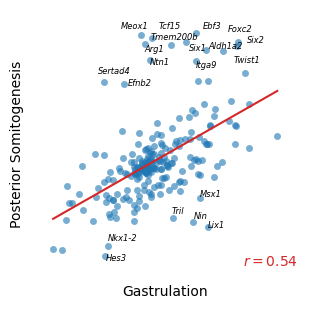

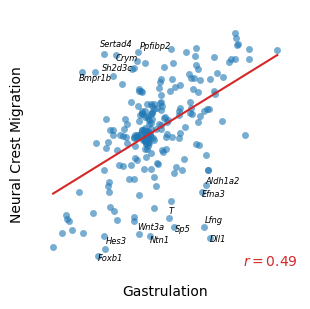

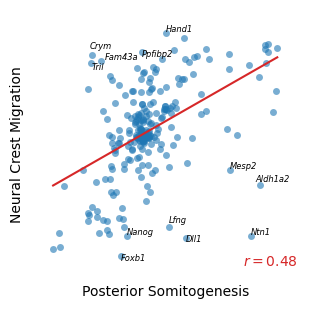

In [18]:
# compare gene expression timing (pairwise)
for xvar, yvar, n in (
    ('GSE162534', 'GSE229103', 20),
    ('GSE162534', 'rRNAModifications', 15),
    ('GSE229103', 'rRNAModifications', 12)):

    # OLS regression
    xx = t.loc[:, xvar].copy()
    yy = t.loc[:, yvar].copy()
    m, b = np.polyfit(xx, yy, 1)
    ols_pred = lambda x: m * x + b
    rval = np.corrcoef(xx, yy)[0, 1].round(2)

    # compute residuals
    res = (yy - ols_pred(xx)).sort_values(
        key = abs, ascending = False)

    # plot gene expression timing (scatter)
    fig, ax = plt.subplots(1, 1, figsize = (3.5, 3.5))
    ax.scatter(xx, yy, s = 25, alpha = .6, linewidth = 0,
               label = 'Mean PseudoTime')

    # plot OLS regression fit (line)
    xx_ols = np.asarray([xx.min(), xx.max()])
    ax.plot(xx_ols, ols_pred(xx_ols), c = 'tab:red',
            label = 'OLS fit')

    # label outliers
    texts = list()
    for lbl in res.head(n).index:
        texts.append(ax.text(
            xx.loc[lbl], yy.loc[lbl],
            lbl, fontsize = 6,
            fontstyle = 'italic'))
    adjust_text(texts = texts)

    ax.text(.99, .04, r'$r=$' + f'{rval}',
            transform = ax.transAxes,
            fontsize = 10, color = 'tab:red',
            ha = 'right', va = 'bottom')
    
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_alpha(0)

    pad = .05
    xlim = ax.get_xlim(); ylim = ax.get_ylim()
    xpad = pad * (xlim[1] - xlim[0])
    ypad = pad * (ylim[1] - ylim[0])
    ax.set_xlim(xlim[0] - xpad, xlim[1] + xpad)
    ax.set_ylim(ylim[0] - ypad, ylim[1] + ypad)

    ax.set_xlabel(names_dict[xvar])
    ax.set_ylabel(names_dict[yvar])
    fn = os.path.join(pth_out, f'{xvar}_v_{yvar}.pdf')
    plt.savefig(fn, bbox_inches = 'tight')

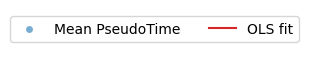

In [10]:
fig, lax = plt.subplots(1, 1, figsize = (1, .5))
lax.legend(*ax.get_legend_handles_labels(), ncol = 2)
lax.axis(False)
fn = os.path.join(pth_out, 'legend.pdf')
plt.savefig(fn, bbox_inches = 'tight')